#Mini projeto varejista Sérgio Elias


##1. Importação e diagnóstico inicial

Nesta etapa, vamos verificar os arquivos disponíveis no ambiente, identificar o CSV de entrada e inspecionar sua estrutura antes de realizar qualquer alteração. Essa verificação é importante para confirmar a origem dos dados e compreender o que cada registro representa.

In [6]:
from google.colab import files
uploaded = files.upload()

Saving pedidos_diagnostico.csv to pedidos_diagnostico.csv


##Sprint 1 — Verificar os arquivos disponíveis

In [7]:
import os

arquivos_csv = [
    arquivo
    for arquivo in os.listdir("/content")
    if arquivo.lower().endswith(".csv")
]

print("Arquivos CSV encontrados:")

for arquivo in arquivos_csv:
    print("-", arquivo)

Arquivos CSV encontrados:
- pedidos_diagnostico.csv


##1.1. Leitura e inspeção inicial da base

Nesta etapa, utilizaremos a biblioteca pandas para ler o arquivo CSV e inspecionar sua estrutura. Vamos visualizar as primeiras linhas, contar os registros e as colunas, identificar os nomes das colunas e verificar os tipos de dados. Essas informações ajudarão a compreender o conteúdo da base antes de qualquer limpeza.

In [8]:
import pandas as pd

###Leitura do arquivo CSV

In [9]:
df = pd.read_csv("pedidos_diagnostico.csv")

###Visualização das primeiras linhas

In [10]:
display(df.head())

,pedido_id,cliente,data_pedido,categoria,valor_compra,quantidade,canal,status
0,P0001,Cliente 01,2026-09-25,Beleza,499.33,5.0,Loja,pendente
1,P0002,Cliente 02,2026-09-20,Moda,654.57,1.0,App,entregue
2,P0003,Cliente 03,2026-09-03,eletronicos,496.24,4.0,Site,entregue
3,P0004,Cliente 04,2026-09-25,Beleza,685.40,3.0,Site,entregue
4,P0005,NaN,2026-09-20,Beleza,157.59,2.0,Loja,entregue


###Quantidade de registros e colunas

In [11]:
print("Quantidade de registros:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

Quantidade de registros: 38
Quantidade de colunas: 8


###Nomes das colunas

In [12]:
print("\nNomes das colunas:")
print(df.columns.tolist())


Nomes das colunas:
['pedido_id', 'cliente', 'data_pedido', 'categoria', 'valor_compra', 'quantidade', 'canal', 'status']


###Tipos de dados

In [13]:
print("\nTipos de dados:")
print(df.dtypes)


Tipos de dados:
pedido_id        object
cliente          object
data_pedido      object
categoria        object
valor_compra    float64
quantidade      float64
canal            object
status           object
dtype: object


##1.2. Diagnóstico da qualidade dos dados

Nesta etapa, vamos identificar valores ausentes, linhas completamente duplicadas, textos vazios ou compostos apenas por espaços e possíveis inconsistências de escrita nas colunas textuais. Os resultados serão registrados antes de qualquer limpeza, permitindo comparar a qualidade da base antes e depois do tratamento.

###Valores ausentes por coluna

In [14]:
print("VALORES AUSENTES POR COLUNA")
print(df.isna().sum())

VALORES AUSENTES POR COLUNA
pedido_id       0
cliente         1
data_pedido     0
categoria       0
valor_compra    2
quantidade      1
canal           0
status          0
dtype: int64


###Quantidade de linhas completamente duplicadas

In [15]:
print("\nLINHAS COMPLETAMENTE DUPLICADAS")
print("Quantidade:", df.duplicated().sum())


LINHAS COMPLETAMENTE DUPLICADAS
Quantidade: 2


###Identificar colunas textuais

In [16]:
colunas_texto = df.select_dtypes(include=["object", "string"]).columns

###Verificar textos vazios ou compostos por espaços

In [17]:
print("\nTEXTOS VAZIOS OU COM APENAS ESPAÇOS")

for coluna in colunas_texto:
    vazios = df[coluna].astype("string").str.strip().eq("").sum()
    print(f"{coluna}: {vazios}")


TEXTOS VAZIOS OU COM APENAS ESPAÇOS
pedido_id: 0
cliente: 1
data_pedido: 0
categoria: 0
canal: 0
status: 0


###Verificar espaços no início ou no final dos textos

In [18]:
print("\nTEXTOS COM ESPAÇOS NO INÍCIO OU NO FINAL")

for coluna in colunas_texto:
    textos = df[coluna].astype("string")
    com_espacos = textos.str.contains(r"^\s|\s$", na=False).sum()
    print(f"{coluna}: {com_espacos}")


TEXTOS COM ESPAÇOS NO INÍCIO OU NO FINAL
pedido_id: 0
cliente: 1
data_pedido: 0
categoria: 1
canal: 2
status: 0


###Mostrar os valores encontrados em cada coluna textual

In [19]:
print("\nVALORES DISTINTOS NAS COLUNAS TEXTUAIS")

for coluna in colunas_texto:
    print(f"\n{coluna}:")
    print(df[coluna].value_counts(dropna=False).to_string())


VALORES DISTINTOS NAS COLUNAS TEXTUAIS

pedido_id:
pedido_id
P0004    2
P0008    2
P0002    1
P0001    1
P0003    1
P0005    1
P0006    1
P0007    1
P0009    1
P0010    1
P0011    1
P0012    1
P0013    1
P0014    1
P0015    1
P0016    1
P0017    1
P0018    1
P0019    1
P0020    1
P0021    1
P0022    1
P0023    1
P0024    1
P0025    1
P0026    1
P0027    1
P0028    1
P0029    1
P0030    1
P0031    1
P0032    1
P0033    1
P0034    1
P0035    1
P0036    1

cliente:
cliente
Cliente 04    2
Cliente 08    2
Cliente 02    1
Cliente 01    1
Cliente 03    1
NaN           1
Cliente 06    1
Cliente 07    1
Cliente 09    1
Cliente 10    1
Cliente 11    1
Cliente 12    1
Cliente 13    1
Cliente 14    1
Cliente 15    1
Cliente 16    1
Cliente 17    1
Cliente 18    1
Cliente 19    1
              1
Cliente 21    1
Cliente 22    1
Cliente 23    1
Cliente 24    1
Cliente 25    1
Cliente 26    1
Cliente 27    1
Cliente 28    1
Cliente 29    1
Cliente 30    1
Cliente 31    1
Cliente 32    1
Cliente 33  

##1.3. Investigação de duplicatas e valores ausentes

Vamos visualizar as linhas completamente duplicadas e verificar se algum identificador de pedido aparece mais de uma vez. Também vamos examinar os registros com informações ausentes para decidir o tratamento adequado sem inventar dados nem excluir informações válidas.

###Exibir as linhas completamente duplicadas

In [20]:
print("LINHAS COMPLETAMENTE DUPLICADAS")
display(df[df.duplicated(keep=False)].sort_values("pedido_id"))

LINHAS COMPLETAMENTE DUPLICADAS


,pedido_id,cliente,data_pedido,categoria,valor_compra,quantidade,canal,status
3,P0004,Cliente 04,2026-09-25,Beleza,685.40,3.0,Site,entregue
36,P0004,Cliente 04,2026-09-25,Beleza,685.40,3.0,Site,entregue
7,P0008,Cliente 08,2026-09-06,Eletrônicos,173.53,4.0,App,entregue
37,P0008,Cliente 08,2026-09-06,Eletrônicos,173.53,4.0,App,entregue


### Verificar pedidos com identificadores repetidos

In [21]:
print("\nPEDIDOS COM ID REPETIDO")
ids_repetidos = df[df.duplicated(subset="pedido_id", keep=False)]
display(ids_repetidos.sort_values("pedido_id"))


PEDIDOS COM ID REPETIDO


,pedido_id,cliente,data_pedido,categoria,valor_compra,quantidade,canal,status
3,P0004,Cliente 04,2026-09-25,Beleza,685.40,3.0,Site,entregue
36,P0004,Cliente 04,2026-09-25,Beleza,685.40,3.0,Site,entregue
7,P0008,Cliente 08,2026-09-06,Eletrônicos,173.53,4.0,App,entregue
37,P0008,Cliente 08,2026-09-06,Eletrônicos,173.53,4.0,App,entregue


###Exibir linhas com valores ausentes

In [22]:
print("\nREGISTROS COM VALORES AUSENTES")
display(df[df.isna().any(axis=1)])


REGISTROS COM VALORES AUSENTES


,pedido_id,cliente,data_pedido,categoria,valor_compra,quantidade,canal,status
4,P0005,NaN,2026-09-20,Beleza,157.59,2.0,Loja,entregue
8,P0009,Cliente 09,2026-09-19,Moda,NaN,5.0,App,entregue
13,P0014,Cliente 14,2026-09-16,Beleza,419.83,NaN,Loja,entregue
24,P0025,Cliente 25,2026-09-08,Eletrônicos,NaN,3.0,Loja,entregue


###Verificar clientes vazios ou com apenas espaços

In [23]:
print("\nCLIENTES VAZIOS OU AUSENTES")
clientes_vazios = df[
    df["cliente"].isna()
    | df["cliente"].astype("string").str.strip().eq("").fillna(False)
]
display(clientes_vazios)


CLIENTES VAZIOS OU AUSENTES


,pedido_id,cliente,data_pedido,categoria,valor_compra,quantidade,canal,status
4,P0005,NaN,2026-09-20,Beleza,157.59,2.0,Loja,entregue
19,P0020,,2026-09-28,Casa,556.01,4.0,Loja,entregue


##1.4. Limpeza e padronização dos dados

Nesta etapa, criaremos uma função reutilizável para tratar inconsistências textuais e remover duplicatas exatas. Os valores ausentes serão preservados, pois não há informações suficientes para preenchê-los com segurança. Ao final, compararemos a quantidade de registros e os problemas de qualidade antes e depois da limpeza.

###Guardar uma cópia da base original para comparação e remover espaços extras dos textos

In [31]:
def limpar_dados(df_entrada):
    dados = df_entrada.copy()

    # Remover espaços extras dos textos
    colunas_texto = dados.select_dtypes(
        include=["object", "string"]
    ).columns

    for coluna in colunas_texto:
        dados[coluna] = dados[coluna].apply(
            lambda valor: valor.strip()
            if isinstance(valor, str)
            else valor
        )

    return dados

     # Transformar textos vazios em valores ausentes
    dados = dados.replace(r"^\s*$", pd.NA, regex=True)

    # Padronizar categorias
    dados["categoria"] = dados["categoria"].replace({
        "eletronicos": "Eletrônicos",
        "ELETRÔNICOS": "Eletrônicos"
    })

    # Padronizar canais de venda
    dados["canal"] = dados["canal"].replace({
        "app": "App",
        "SITE": "Site",
        "site": "Site",
        "loja": "Loja"
    })

    # Remover somente linhas totalmente duplicadas
    dados = dados.drop_duplicates().reset_index(drop=True)

    return dados


df = limpar_dados(df_original)

print("LIMPEZA CONCLUÍDA")
print("Registros antes:", len(df_original))
print("Registros depois:", len(df))
print("Linhas removidas:", len(df_original) - len(df))

print("\nVALORES AUSENTES APÓS A LIMPEZA")
print(df.isna().sum())

print("\nCATEGORIAS APÓS A PADRONIZAÇÃO")
print(df["categoria"].value_counts(dropna=False))

print("\nCANAIS APÓS A PADRONIZAÇÃO")
print(df["canal"].value_counts(dropna=False))

print("\nDUPLICATAS RESTANTES:", df.duplicated().sum())


LIMPEZA CONCLUÍDA
Registros antes: 38
Registros depois: 38
Linhas removidas: 0

VALORES AUSENTES APÓS A LIMPEZA
pedido_id       0
cliente         1
data_pedido     0
categoria       0
valor_compra    2
quantidade      1
canal           0
status          0
dtype: int64

CATEGORIAS APÓS A PADRONIZAÇÃO
categoria
Beleza         13
Moda           11
Eletrônicos     7
Casa            5
eletronicos     1
ELETRÔNICOS     1
Name: count, dtype: int64

CANAIS APÓS A PADRONIZAÇÃO
canal
Loja    16
Site    12
App      8
app      1
SITE     1
Name: count, dtype: int64

DUPLICATAS RESTANTES: 2


### Verificação de registros duplicados

Nesta etapa, vamos identificar as linhas duplicadas da base de dados, considerando todas as colunas. O objetivo é entender por que ainda existem registros repetidos após a limpeza e evitar excluir dados sem antes verificar suas diferenças.

In [32]:
# Identificar todas as linhas que possuem duplicatas
duplicatas = df[df.duplicated(keep=False)]

print("REGISTROS DUPLICADOS")
display(duplicatas.sort_values(by="pedido_id"))

print("Quantidade de linhas envolvidas:", len(duplicatas))

REGISTROS DUPLICADOS


,pedido_id,cliente,data_pedido,categoria,valor_compra,quantidade,canal,status
3,P0004,Cliente 04,2026-09-25,Beleza,685.40,3.0,Site,entregue
36,P0004,Cliente 04,2026-09-25,Beleza,685.40,3.0,Site,entregue
7,P0008,Cliente 08,2026-09-06,Eletrônicos,173.53,4.0,App,entregue
37,P0008,Cliente 08,2026-09-06,Eletrônicos,173.53,4.0,App,entregue


Quantidade de linhas envolvidas: 4


### Correção da limpeza e padronização dos dados

Nesta etapa, vamos atualizar a função de limpeza para remover espaços extras, tratar textos vazios, padronizar categorias e canais de venda e remover registros totalmente duplicados. Ao final, vamos comparar a quantidade de registros antes e depois da limpeza e verificar os valores ausentes.

In [33]:
def limpar_dados(df_entrada):
    """Limpa textos, padroniza categorias e canais e remove duplicatas."""

    dados = df_entrada.copy()

    # 1. Remover espaços extras dos textos
    colunas_texto = dados.select_dtypes(
        include=["object", "string"]
    ).columns

    for coluna in colunas_texto:
        dados[coluna] = dados[coluna].apply(
            lambda valor: valor.strip()
            if isinstance(valor, str)
            else valor
        )

    # 2. Transformar textos vazios em valores ausentes
    dados = dados.replace(r"^\s*$", pd.NA, regex=True)

    # 3. Padronizar categorias
    dados["categoria"] = dados["categoria"].replace({
        "eletronicos": "Eletrônicos",
        "ELETRÔNICOS": "Eletrônicos"
    })

    # 4. Padronizar canais de venda
    dados["canal"] = dados["canal"].replace({
        "app": "App",
        "APP": "App",
        "SITE": "Site",
        "site": "Site",
        "loja": "Loja"
    })

    # 5. Remover registros totalmente duplicados
    dados = dados.drop_duplicates().reset_index(drop=True)

    return dados


# Executar a limpeza usando a base original
df = limpar_dados(df_original)

# 6. Conferir os resultados
print("LIMPEZA CONCLUÍDA")
print("Registros antes:", len(df_original))
print("Registros depois:", len(df))
print("Linhas removidas:", len(df_original) - len(df))

print("\nVALORES AUSENTES")
print(df.isna().sum())

print("\nCATEGORIAS PADRONIZADAS")
print(df["categoria"].value_counts(dropna=False))

print("\nCANAIS PADRONIZADOS")
print(df["canal"].value_counts(dropna=False))

print("\nDUPLICATAS RESTANTES:", df.duplicated().sum())

LIMPEZA CONCLUÍDA
Registros antes: 38
Registros depois: 36
Linhas removidas: 2

VALORES AUSENTES
pedido_id       0
cliente         2
data_pedido     0
categoria       0
valor_compra    2
quantidade      1
canal           0
status          0
dtype: int64

CATEGORIAS PADRONIZADAS
categoria
Beleza         12
Moda           11
Eletrônicos     8
Casa            5
Name: count, dtype: int64

CANAIS PADRONIZADOS
canal
Loja    16
Site    12
App      8
Name: count, dtype: int64

DUPLICATAS RESTANTES: 0


### Análise de valores ausentes

Nesta etapa, vamos identificar os registros que possuem informações ausentes nas colunas cliente, valor da compra e quantidade. Essa análise permitirá avaliar quais dados podem ser recuperados, quais precisam de tratamento e quais decisões são adequadas antes de calcular indicadores de vendas.

In [34]:
# Identificar registros com pelo menos um valor ausente
dados_ausentes = df[df.isna().any(axis=1)]

print("REGISTROS COM VALORES AUSENTES")
display(dados_ausentes)

print("\nTOTAL DE REGISTROS COM AUSÊNCIAS:")
print(len(dados_ausentes))

print("\nPERCENTUAL DE VALORES AUSENTES POR COLUNA:")
percentual_ausentes = (
    df.isna().mean().mul(100).round(2)
)

print(percentual_ausentes[percentual_ausentes > 0])

REGISTROS COM VALORES AUSENTES


,pedido_id,cliente,data_pedido,categoria,valor_compra,quantidade,canal,status
4,P0005,NaN,2026-09-20,Beleza,157.59,2.0,Loja,entregue
8,P0009,Cliente 09,2026-09-19,Moda,NaN,5.0,App,entregue
13,P0014,Cliente 14,2026-09-16,Beleza,419.83,NaN,Loja,entregue
19,P0020,<NA>,2026-09-28,Casa,556.01,4.0,Loja,entregue
24,P0025,Cliente 25,2026-09-08,Eletrônicos,NaN,3.0,Loja,entregue



TOTAL DE REGISTROS COM AUSÊNCIAS:
5

PERCENTUAL DE VALORES AUSENTES POR COLUNA:
cliente         5.56
valor_compra    5.56
quantidade      2.78
dtype: float64


### Investigação dos dados ausentes

Vamos examinar as estatísticas descritivas das colunas numéricas e verificar a distribuição dos valores de compra e das quantidades. O objetivo é compreender os dados disponíveis antes de decidir como tratar os registros incompletos, evitando preencher informações com valores arbitrários.

In [35]:
# Estatísticas descritivas das colunas numéricas
print("ESTATÍSTICAS DOS DADOS NUMÉRICOS")

display(
    df[["valor_compra", "quantidade"]].describe()
)

# Visualizar os pedidos com valor de compra conhecido
print("\nVALORES DE COMPRA DISPONÍVEIS")

display(
    df[["pedido_id", "valor_compra", "quantidade"]]
    .sort_values(by="pedido_id")
)

ESTATÍSTICAS DOS DADOS NUMÉRICOS


,valor_compra,quantidade
count,34.000000,35.000000
mean,465.902059,3.142857
std,229.699088,1.611409
min,90.030000,1.000000
25%,322.990000,1.000000
50%,456.255000,3.000000
75%,598.842500,5.000000
max,943.300000,5.000000



VALORES DE COMPRA DISPONÍVEIS


,pedido_id,valor_compra,quantidade
0,P0001,499.33,5.0
1,P0002,654.57,1.0
2,P0003,496.24,4.0
3,P0004,685.40,3.0
4,P0005,157.59,2.0
5,P0006,266.41,5.0
6,P0007,674.58,1.0
7,P0008,173.53,4.0
8,P0009,NaN,5.0
9,P0010,379.41,4.0


### Verificação e ajuste dos tipos de dados

Nesta etapa, vamos conferir os tipos de dados de cada coluna e verificar se a data do pedido está no formato adequado. Também vamos investigar se a coluna quantidade pode ser representada por números inteiros, preservando os valores ausentes e sem alterar os dados originais.

In [36]:
# Verificar os tipos de dados atuais
print("TIPOS DE DADOS")
print(df.dtypes)

# Verificar alguns registros da base
print("\nAMOSTRA DOS DADOS")
display(df.head())

# Conferir o formato da coluna de data
print("\nTIPO ATUAL DA DATA:")
print(df["data_pedido"].dtype)

TIPOS DE DADOS
pedido_id        object
cliente          object
data_pedido      object
categoria        object
valor_compra    float64
quantidade      float64
canal            object
status           object
dtype: object

AMOSTRA DOS DADOS


,pedido_id,cliente,data_pedido,categoria,valor_compra,quantidade,canal,status
0,P0001,Cliente 01,2026-09-25,Beleza,499.33,5.0,Loja,pendente
1,P0002,Cliente 02,2026-09-20,Moda,654.57,1.0,App,entregue
2,P0003,Cliente 03,2026-09-03,Eletrônicos,496.24,4.0,Site,entregue
3,P0004,Cliente 04,2026-09-25,Beleza,685.40,3.0,Site,entregue
4,P0005,NaN,2026-09-20,Beleza,157.59,2.0,Loja,entregue



TIPO ATUAL DA DATA:
object


### Ajuste dos tipos de dados

Vamos converter a coluna `data_pedido` para o tipo datetime, permitindo analisar as vendas por dia, mês e período. Também vamos converter `quantidade` para o tipo inteiro anulável do Pandas (`Int64`), que aceita números inteiros e mantém os valores ausentes. Ao final, vamos conferir os tipos atualizados e verificar se a conversão ocorreu corretamente.

In [37]:
# Converter a coluna de data
df["data_pedido"] = pd.to_datetime(
    df["data_pedido"],
    errors="coerce"
)

# Converter quantidade para inteiro, preservando ausências
df["quantidade"] = df["quantidade"].astype("Int64")

# Conferir os tipos atualizados
print("TIPOS DE DADOS APÓS A CONVERSÃO")
print(df.dtypes)

print("\nVERIFICAÇÃO DAS DATAS")
display(df[["pedido_id", "data_pedido"]].head())

print("\nVERIFICAÇÃO DAS QUANTIDADES")
display(df[["pedido_id", "quantidade"]].head())

print("\nVALORES AUSENTES")
print(df.isna().sum())

TIPOS DE DADOS APÓS A CONVERSÃO
pedido_id               object
cliente                 object
data_pedido     datetime64[ns]
categoria               object
valor_compra           float64
quantidade               Int64
canal                   object
status                  object
dtype: object

VERIFICAÇÃO DAS DATAS


,pedido_id,data_pedido
0,P0001,2026-09-25
1,P0002,2026-09-20
2,P0003,2026-09-03
3,P0004,2026-09-25
4,P0005,2026-09-20



VERIFICAÇÃO DAS QUANTIDADES


,pedido_id,quantidade
0,P0001,5
1,P0002,1
2,P0003,4
3,P0004,3
4,P0005,2



VALORES AUSENTES
pedido_id       0
cliente         2
data_pedido     0
categoria       0
valor_compra    2
quantidade      1
canal           0
status          0
dtype: int64


### Análise exploratória: pedidos por categoria

Nesta etapa, vamos contar quantos pedidos existem em cada categoria de produto e calcular sua participação percentual no total de pedidos. Essa análise permitirá identificar quais categorias aparecem com maior frequência na base de vendas.

Como cada linha representa um pedido após a remoção das duplicatas, utilizaremos a contagem de registros por categoria. Ainda não estamos calculando o faturamento, pois existem valores de compra ausentes que precisam ser considerados nas próximas análises.

In [38]:
# Contar pedidos por categoria
pedidos_categoria = (
    df["categoria"]
    .value_counts()
    .rename_axis("categoria")
    .reset_index(name="quantidade_pedidos")
)

# Calcular a participação percentual
pedidos_categoria["percentual"] = (
    pedidos_categoria["quantidade_pedidos"]
    / len(df)
    * 100
).round(2)

# Exibir o resultado
print("PEDIDOS POR CATEGORIA")
display(pedidos_categoria)

PEDIDOS POR CATEGORIA


,categoria,quantidade_pedidos,percentual
0,Beleza,12,33.33
1,Moda,11,30.56
2,Eletrônicos,8,22.22
3,Casa,5,13.89


### Análise do valor das compras por categoria

Nesta etapa, vamos calcular o valor total e o valor médio das compras em cada categoria, além de contar quantos pedidos possuem valor informado. Os valores ausentes serão ignorados nos cálculos monetários, e a quantidade de pedidos com valor disponível será apresentada para contextualizar os resultados.

In [39]:
# Agrupar os pedidos por categoria
analise_categoria = (
    df.groupby("categoria")
    .agg(
        quantidade_pedidos=("pedido_id", "count"),
        pedidos_com_valor=("valor_compra", "count"),
        faturamento_observado=("valor_compra", "sum"),
        ticket_medio=("valor_compra", "mean")
    )
    .reset_index()
)

# Formatar os valores monetários para duas casas decimais
analise_categoria["faturamento_observado"] = (
    analise_categoria["faturamento_observado"].round(2)
)

analise_categoria["ticket_medio"] = (
    analise_categoria["ticket_medio"].round(2)
)

# Ordenar pelo faturamento observado, do maior para o menor
analise_categoria = analise_categoria.sort_values(
    by="faturamento_observado",
    ascending=False
)

print("ANÁLISE DE VALORES POR CATEGORIA")
display(analise_categoria)

ANÁLISE DE VALORES POR CATEGORIA


,categoria,quantidade_pedidos,pedidos_com_valor,faturamento_observado,ticket_medio
0,Beleza,12,12,6385.18,532.10
3,Moda,11,10,4694.71,469.47
2,Eletrônicos,8,7,2504.68,357.81
1,Casa,5,5,2256.10,451.22


### Análise exploratória: desempenho dos canais de venda

Nesta etapa, vamos agrupar os pedidos por canal de venda e calcular a quantidade de pedidos, o número de pedidos com valor informado, o faturamento observado e o ticket médio. Essa análise permitirá comparar o desempenho dos canais Loja, Site e App, considerando os valores ausentes.

In [40]:
# Agrupar os pedidos por canal de venda
analise_canal = (
    df.groupby("canal")
    .agg(
        quantidade_pedidos=("pedido_id", "count"),
        pedidos_com_valor=("valor_compra", "count"),
        faturamento_observado=("valor_compra", "sum"),
        ticket_medio=("valor_compra", "mean")
    )
    .reset_index()
)

# Arredondar os valores monetários
analise_canal["faturamento_observado"] = (
    analise_canal["faturamento_observado"].round(2)
)

analise_canal["ticket_medio"] = (
    analise_canal["ticket_medio"].round(2)
)

# Ordenar pelo faturamento observado
analise_canal = analise_canal.sort_values(
    by="faturamento_observado",
    ascending=False
)

print("DESEMPENHO DOS CANAIS DE VENDA")
display(analise_canal)

DESEMPENHO DOS CANAIS DE VENDA


,canal,quantidade_pedidos,pedidos_com_valor,faturamento_observado,ticket_medio
1,Loja,16,15,7559.00,503.93
2,Site,12,12,5605.92,467.16
0,App,8,7,2675.75,382.25


### Análise temporal: pedidos por dia

Nesta etapa, vamos agrupar os pedidos pela data da compra para identificar quantos pedidos foram registrados em cada dia. Essa análise ajuda a observar a distribuição temporal das vendas e a identificar dias com maior ou menor volume de pedidos. A contagem será baseada nos pedidos únicos após a remoção das duplicatas completas.

In [41]:
# Contar pedidos por dia
pedidos_por_dia = (
    df.groupby("data_pedido")
    .agg(
        quantidade_pedidos=("pedido_id", "nunique"),
        faturamento_observado=("valor_compra", "sum")
    )
    .reset_index()
    .sort_values(by="data_pedido")
)

# Arredondar o faturamento para duas casas decimais
pedidos_por_dia["faturamento_observado"] = (
    pedidos_por_dia["faturamento_observado"].round(2)
)

print("PEDIDOS E FATURAMENTO OBSERVADO POR DIA")
display(pedidos_por_dia)

print("\nDIA COM MAIS PEDIDOS")
display(
    pedidos_por_dia[
        pedidos_por_dia["quantidade_pedidos"]
        == pedidos_por_dia["quantidade_pedidos"].max()
    ]
)

PEDIDOS E FATURAMENTO OBSERVADO POR DIA


,data_pedido,quantidade_pedidos,faturamento_observado
0,2026-09-01,3,1468.53
1,2026-09-02,1,316.43
2,2026-09-03,2,713.93
3,2026-09-06,1,173.53
4,2026-09-07,2,1043.00
5,2026-09-08,3,1245.16
6,2026-09-12,2,751.71
7,2026-09-13,1,941.36
8,2026-09-15,2,940.99
9,2026-09-16,2,1276.13



DIA COM MAIS PEDIDOS


,data_pedido,quantidade_pedidos,faturamento_observado
0,2026-09-01,3,1468.53
5,2026-09-08,3,1245.16
17,2026-09-25,3,1715.76


### Visualização: quantidade de pedidos por dia

Vamos utilizar a biblioteca Matplotlib para criar um gráfico de barras com a quantidade de pedidos registrados em cada dia de setembro de 2026. O gráfico permitirá comparar visualmente o movimento diário e destacar os dias com maior volume de pedidos.

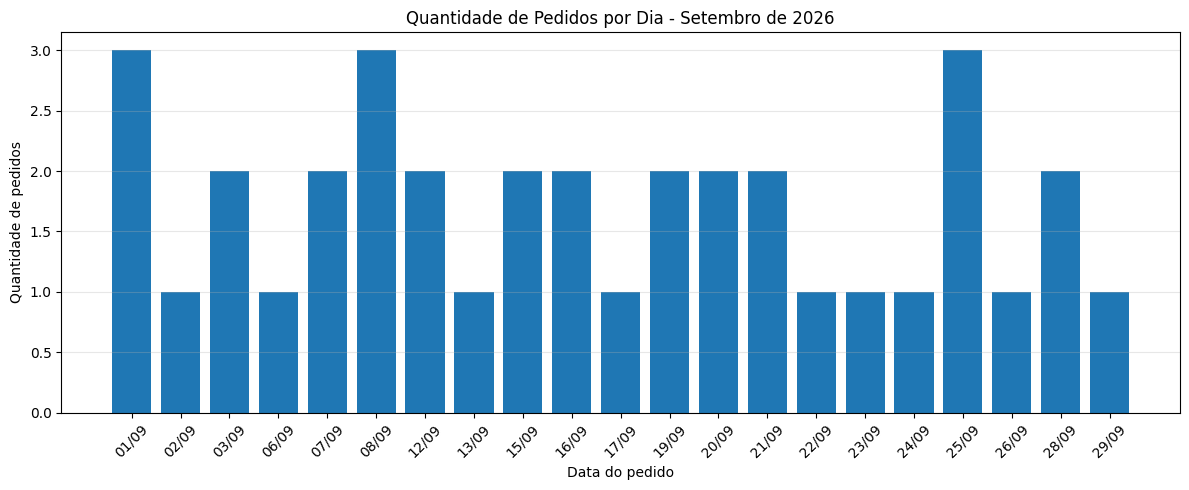

In [42]:
import matplotlib.pyplot as plt

# Criar o gráfico de barras
plt.figure(figsize=(12, 5))

plt.bar(
    pedidos_por_dia["data_pedido"].dt.strftime("%d/%m"),
    pedidos_por_dia["quantidade_pedidos"]
)

# Configurar título e eixos
plt.title("Quantidade de Pedidos por Dia - Setembro de 2026")
plt.xlabel("Data do pedido")
plt.ylabel("Quantidade de pedidos")

# Melhorar a leitura das datas
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Visualização: faturamento por dia

Nesta etapa, utilizaremos a biblioteca Matplotlib para criar um gráfico de linhas que representa o faturamento observado em cada dia de setembro de 2026. Essa visualização permitirá identificar variações no faturamento diário e observar os dias com maiores e menores valores.

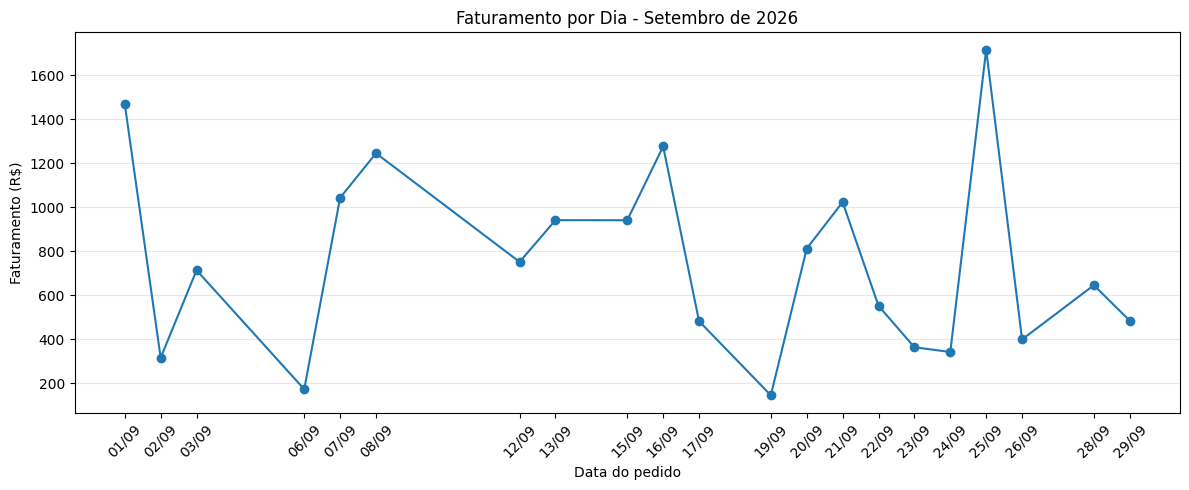

In [43]:

# Criar o gráfico de linhas do faturamento diário
plt.figure(figsize=(12, 5))

plt.plot(
    pedidos_por_dia["data_pedido"],
    pedidos_por_dia["faturamento_observado"],
    marker="o"
)

# Configurar título e eixos
plt.title("Faturamento por Dia - Setembro de 2026")
plt.xlabel("Data do pedido")
plt.ylabel("Faturamento (R$)")

# Melhorar a leitura
plt.xticks(
    pedidos_por_dia["data_pedido"],
    pedidos_por_dia["data_pedido"].dt.strftime("%d/%m"),
    rotation=45
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Análise: dias de maior e menor faturamento

Nesta etapa, utilizaremos o Pandas para identificar os dias com maior e menor faturamento observado em setembro de 2026. Essa análise ajudará a compreender as variações das vendas e a identificar os dias de melhor e pior desempenho financeiro.

In [44]:

# Identificar o dia de maior faturamento
dia_maior_faturamento = pedidos_por_dia.loc[
    pedidos_por_dia["faturamento_observado"].idxmax()
]

# Identificar o dia de menor faturamento
dia_menor_faturamento = pedidos_por_dia.loc[
    pedidos_por_dia["faturamento_observado"].idxmin()
]

# Exibir os resultados
print("DIA DE MAIOR FATURAMENTO")
print("Data:", dia_maior_faturamento["data_pedido"].strftime("%d/%m/%Y"))
print("Faturamento: R$", round(dia_maior_faturamento["faturamento_observado"], 2))

print("\nDIA DE MENOR FATURAMENTO")
print("Data:", dia_menor_faturamento["data_pedido"].strftime("%d/%m/%Y"))
print("Faturamento: R$", round(dia_menor_faturamento["faturamento_observado"], 2))


DIA DE MAIOR FATURAMENTO
Data: 25/09/2026
Faturamento: R$ 1715.76

DIA DE MENOR FATURAMENTO
Data: 19/09/2026
Faturamento: R$ 146.26


### Análise: faturamento total e médio diário

Nesta etapa, utilizaremos o Pandas para calcular o faturamento total observado em setembro de 2026 e o faturamento médio por dia registrado na tabela de análise. Esses indicadores ajudam a compreender o desempenho financeiro do período.

In [45]:

# Calcular o faturamento total do período
faturamento_total = pedidos_por_dia["faturamento_observado"].sum()

# Calcular o faturamento médio diário
faturamento_medio = pedidos_por_dia["faturamento_observado"].mean()

# Exibir os resultados
print("FATURAMENTO TOTAL DO PERÍODO")
print("R$", round(faturamento_total, 2))

print("\nFATURAMENTO MÉDIO DIÁRIO")
print("R$", round(faturamento_medio, 2))


FATURAMENTO TOTAL DO PERÍODO
R$ 15840.67

FATURAMENTO MÉDIO DIÁRIO
R$ 754.32


### Análise: quantidade total e média de pedidos

Nesta etapa, utilizaremos o Pandas para calcular a quantidade total de pedidos registrados e a média diária de pedidos. Esses indicadores ajudarão a compreender o volume de vendas durante o período analisado.

In [46]:

# Calcular a quantidade total de pedidos
total_pedidos = pedidos_por_dia["quantidade_pedidos"].sum()

# Calcular a média diária de pedidos
media_pedidos_dia = pedidos_por_dia["quantidade_pedidos"].mean()

# Exibir os resultados
print("QUANTIDADE TOTAL DE PEDIDOS")
print(total_pedidos)

print("\nMÉDIA DE PEDIDOS POR DIA")
print(round(media_pedidos_dia, 2))


QUANTIDADE TOTAL DE PEDIDOS
36

MÉDIA DE PEDIDOS POR DIA
1.71


### Exportação da base tratada

Nesta etapa, exportaremos a base de dados após a limpeza para um arquivo CSV chamado `varejo_limpo.csv`. O arquivo será salvo sem o índice do Pandas, permitindo sua reutilização em outras ferramentas e análises. Também compararemos a quantidade de registros antes e depois do tratamento.

In [48]:
# Quantidade de registros antes da limpeza
registros_antes = len(df_original)

# Quantidade de registros após a limpeza
registros_depois = len(df)

# Exportar a base tratada
df.to_csv("varejo_limpo.csv", index=False)

# Exibir a conferência
print("Registros antes da limpeza:", registros_antes)
print("Registros depois da limpeza:", registros_depois)
print("Arquivo varejo_limpo.csv exportado com sucesso!")

Registros antes da limpeza: 38
Registros depois da limpeza: 36
Arquivo varejo_limpo.csv exportado com sucesso!


In [49]:

from google.colab import files

files.download("varejo_limpo.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>